# 1. Horizon x bins grid (JPM)

For every horizon h and number of output bins N, compare the state-conditioned net, the state-free net
and three count baselines (marginal, additive smoothing, backoff) on held-out log-likelihood.

The label is the h-day return from t+1 to t+1+h. The earlier version of this grid
(`archive/results/master_grid_results_leaky_label.csv`) used the return from t to t+h, which contains
the same day as the state X_t, so the count baselines could read part of the label from the state.

In [1]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "markov").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from markov.data import load_jpm, splits_by_horizon, standardize, return_states, forward_labels
from markov.models import make_model
from markov.train import loaders, fit
from markov.metrics import baselines, evaluate
from markov.plots import save

HORIZONS = [1, 2, 5, 10]
N_BINS = [10, 20, 35, 55]
SEED = 42
ALPHAS = [1e-6, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 5.0, 10.0]
TAUS = [10, 50, 100, 200, 500, 1000]
OUT = ROOT / "results/single_asset/grid"
FIG = ROOT / "figures/single_asset/grid"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
prices, F, cols = load_jpm()
sp = splits_by_horizon(len(prices) - 1, HORIZONS)
F = standardize(F, sp[1]["idx_train"])
X, n_x, edges_x = return_states(prices, 55, len(sp[1]["idx_train"]))
configs = forward_labels(prices, sp, N_BINS)
print(f"{len(prices)} days, {F.shape[1]} features, {n_x} states")
for h in HORIZONS:
    print(f"h={h}: train {len(sp[h]['idx_train'])}, val {len(sp[h]['idx_val'])}, test {len(sp[h]['idx_test'])}")

2369 days, 194 features, 55 states
h=1: train 1656, val 355, test 356
h=2: train 1656, val 355, test 355
h=5: train 1654, val 354, test 355
h=10: train 1650, val 354, test 354


In [3]:
# same day in state and label would show up as a large fraction of X_t == Y_t at h=1
c = configs[(1, 55)]
print("share of X_t == Y_t at h=1, N=55:", round(float((X[:c["T"]] == c["y_all"]).mean()), 4))

share of X_t == Y_t at h=1, N=55: 0.0207


In [4]:
hist_path = OUT / "histories.json"
histories = json.loads(hist_path.read_text()) if hist_path.exists() else {}
rows = []

for h in HORIZONS:
    for N in N_BINS:
        c = configs[(h, N)]
        n = c["N_actual"]
        torch.manual_seed(SEED)
        np.random.seed(SEED)
        tr, va, te = loaders(F, X, c["y_all"], c)
        base = {"h": h, "N": N, "N_actual": n, "sigma": c["sigma"],
                "n_train": len(c["idx_train"]), "n_val": len(c["idx_val"]), "n_test": len(c["idx_test"])}

        bl = baselines(c, X, n_x, ALPHAS, TAUS)
        marg = bl["marginal"]["test_ll"]
        for name, r in bl.items():
            rows.append({**base, "model": name, "test_ll": r["test_ll"], "delta_ll": r["test_ll"] - marg,
                         "val_ll": r["val_ll"], "accuracy": r["accuracy"], "severity": r["severity"],
                         "alpha": r.get("alpha"), "tau": r.get("tau")})

        for kind in ["state_cond", "state_free"]:
            torch.manual_seed(SEED)
            model = make_model(kind, F.shape[1], n_x, n)
            model, hist = fit(model, OUT / f"cache/{kind}_h{h}_N{N}.pt", tr, va, n, c["sigma"], DEVICE)
            if hist is not None:
                histories[f"{kind}_h{h}_N{N}"] = {k: hist[k] for k in ["train_loss", "val_loss"]}
            test, val = evaluate(model, te, n, DEVICE), evaluate(model, va, n, DEVICE)
            rows.append({**base, "model": f"{kind}_nn", "test_ll": test["mean_ll"], "delta_ll": test["mean_ll"] - marg,
                         "val_ll": val["mean_ll"], "accuracy": test["accuracy"], "severity": test["severity"]})
        print(f"h={h:>2} N={N:>2}  backoff {bl['backoff']['test_ll'] - marg:+.4f}  "
              f"state_cond {rows[-2]['delta_ll']:+.4f}  state_free {rows[-1]['delta_ll']:+.4f}")

grid = pd.DataFrame(rows)
grid.to_csv(OUT / "grid_results.csv", index=False)
hist_path.write_text(json.dumps(histories))

h= 1 N=10  backoff +0.0016  state_cond -0.0012  state_free -0.0082


h= 1 N=20  backoff +0.0001  state_cond -0.0615  state_free -0.0026


h= 1 N=35  backoff +0.0001  state_cond -0.0161  state_free -0.0348


h= 1 N=55  backoff +0.0003  state_cond -0.0073  state_free -0.0448


h= 2 N=10  backoff +0.0034  state_cond -0.0009  state_free -0.0042


...

h=10 N=10  backoff +0.0003  state_cond -0.0051  state_free -0.0050


h=10 N=20  backoff -0.0001  state_cond +0.0022  state_free -0.0429


h=10 N=35  backoff +0.0001  state_cond -0.0284  state_free -0.0084


h=10 N=55  backoff +0.0001  state_cond +0.0218  state_free +0.0125


23535

## Delta log-likelihood vs the marginal (positive = better than marginal)

In [5]:
for model in ["state_cond_nn", "state_free_nn", "backoff", "additive"]:
    print(model)
    print(grid[grid.model == model].pivot(index="h", columns="N", values="delta_ll").round(4), "\n")

state_cond_nn
N       10      20      35      55
h                                 
1  -0.0012 -0.0615 -0.0161 -0.0073
2  -0.0009 -0.0853 -0.0290 -0.0360
5  -0.0049 -0.0922 -0.1175 -0.0085
10 -0.0051  0.0022 -0.0284  0.0218 

state_free_nn
N       10      20      35      55
h                                 
1  -0.0082 -0.0026 -0.0348 -0.0448
2  -0.0042 -0.0002 -0.0297 -0.0365
5  -0.0214 -0.0426 -0.0677 -0.0359
10 -0.0050 -0.0429 -0.0084  0.0125 

backoff
N       10      20      35      55
h                                 
1   0.0016  0.0001  0.0001  0.0003
2   0.0034  0.0000 -0.0010 -0.0020
5  -0.0000  0.0006  0.0002 -0.0025
10  0.0003 -0.0001  0.0001  0.0001 

additive
N       10      20      35      55
h                                 
1   0.0037 -0.0027 -0.0002  0.0074
2   0.0024 -0.0029 -0.0025 -0.0033
5  -0.0083 -0.0000  0.0023 -0.0031
10  0.0006 -0.0082 -0.0004 -0.0003 



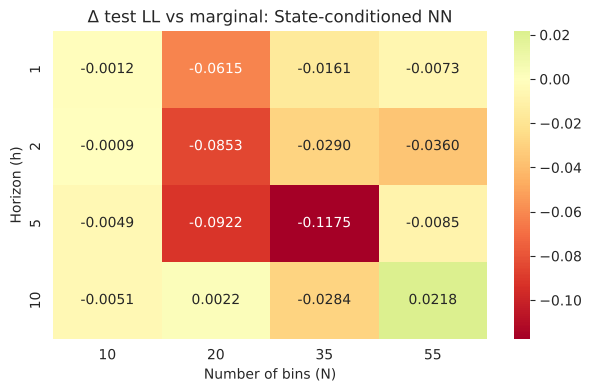

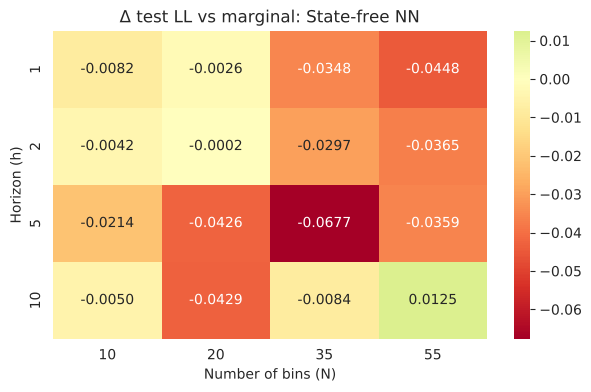

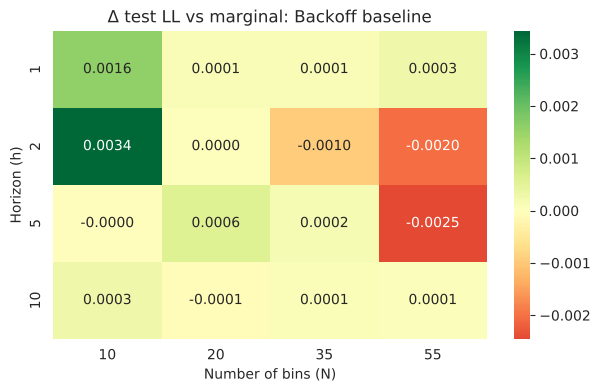

In [6]:
sns.set_style("whitegrid")
for model, title, stem in [("state_cond_nn", "State-conditioned NN", "A_heatmap_state_cond"),
                           ("state_free_nn", "State-free NN", "B_heatmap_state_free"),
                           ("backoff", "Backoff baseline", "C_heatmap_backoff")]:
    pivot = grid[grid.model == model].pivot(index="h", columns="N", values="delta_ll")
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.heatmap(pivot, annot=True, fmt=".4f", cmap="RdYlGn", center=0, ax=ax)
    ax.set_title(rf"$\Delta$ test LL vs marginal: {title}")
    ax.set_xlabel("Number of bins (N)")
    ax.set_ylabel("Horizon (h)")
    save(fig, FIG / stem)
    plt.show()

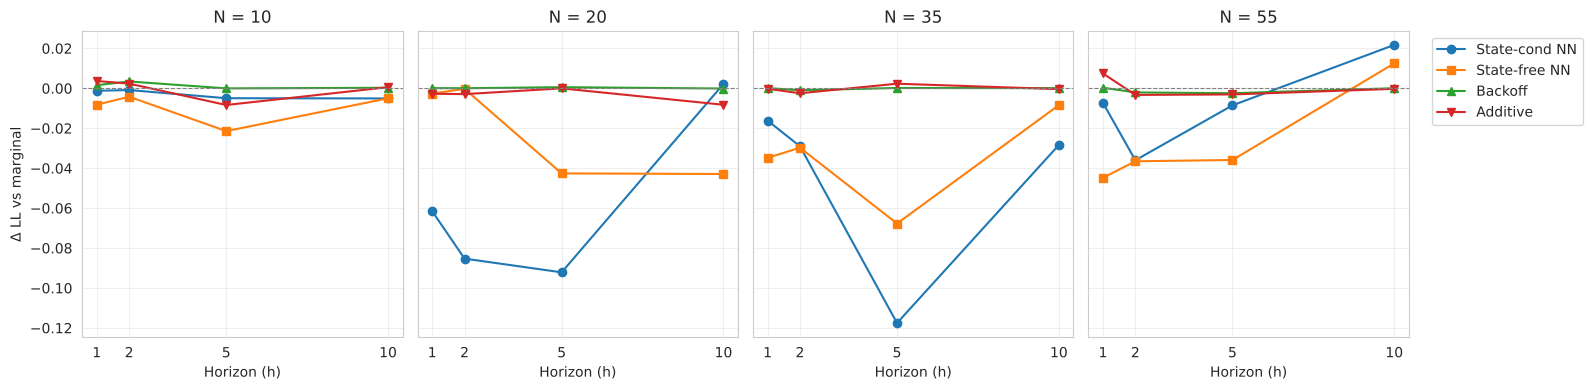

In [7]:
fig, axes = plt.subplots(1, len(N_BINS), figsize=(4 * len(N_BINS), 4), sharey=True)
for ax, N in zip(axes, N_BINS):
    for model, label, marker in [("state_cond_nn", "State-cond NN", "o"), ("state_free_nn", "State-free NN", "s"),
                                 ("backoff", "Backoff", "^"), ("additive", "Additive", "v")]:
        sub = grid[(grid.model == model) & (grid.N == N)].sort_values("h")
        ax.plot(sub.h, sub.delta_ll, marker=marker, label=label)
    ax.axhline(0, color="gray", ls="--", lw=0.8)
    ax.set_title(f"N = {N}")
    ax.set_xlabel("Horizon (h)")
    ax.set_xticks(HORIZONS)
axes[0].set_ylabel(r"$\Delta$ LL vs marginal")
axes[-1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
fig.tight_layout()
save(fig, FIG / "D_line_delta_ll_vs_horizon")
plt.show()

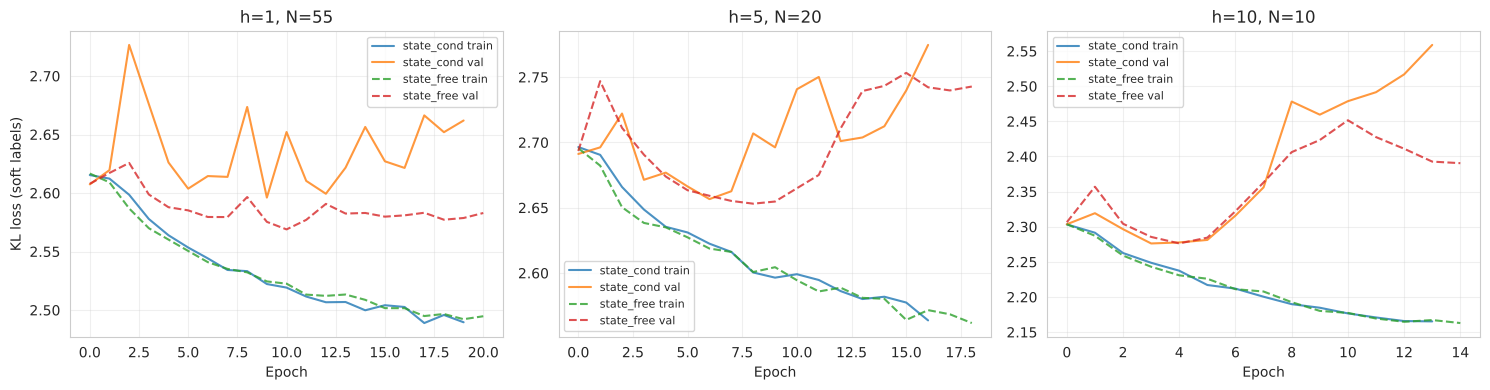

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (h, N) in zip(axes, [(1, 55), (5, 20), (10, 10)]):
    for kind, ls in [("state_cond", "-"), ("state_free", "--")]:
        hist = histories[f"{kind}_h{h}_N{N}"]
        ax.plot(hist["train_loss"], ls, label=f"{kind} train", alpha=0.8)
        ax.plot(hist["val_loss"], ls, label=f"{kind} val", alpha=0.8)
    ax.set_title(f"h={h}, N={N}")
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("KL loss (soft labels)")
fig.tight_layout()
save(fig, FIG / "E_training_curves")
plt.show()

In [9]:
nn = grid[grid.model.isin(["state_cond_nn", "state_free_nn"])]
print("NN settings that beat the marginal:")
print(nn[nn.delta_ll > 0][["h", "N", "model", "delta_ll"]].to_string(index=False))

NN settings that beat the marginal:
 h  N         model  delta_ll
10 20 state_cond_nn  0.002162
10 55 state_cond_nn  0.021751
10 55 state_free_nn  0.012510
